# 02: Data Cleaning, Pure Python Parser & Hypothesis Testing
**Syllabus Coverage:** Unit III (Cleaning & Prep) & Unit IV (Python Core & Benchmarking)

### Objectives:
1. Detect and impute missing sensor telemetry values (time-series linear interpolation & forward fill).
2. Detect and scrub statistical outliers using the $1.5 \times \text{IQR}$ rule.
3. Implement cyclical hour encodings ($h_{\sin}, h_{\cos}$) to resolve 23:00 to 00:00 boundary discontinuity.
4. Perform Welch's $t$-test ($H_0: \mu_{\text{peak}} = \mu_{\text{off-peak}}$) proving peak power is dirtier.
5. Build and benchmark a pure Python CSV parser (lists and dicts) against Pandas `read_csv`.
6. Demonstrate NumPy 2D array indexing and slicing.

In [1]:
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.insert(0, os.path.abspath('..'))
from src.ingestion import load_raw_data, parse_csv_pure_python, benchmark_csv_parsers
from src.preprocessing import detect_and_impute_missing, scrub_iqr_outliers, add_cyclical_features
from src.statistics import run_welchs_ttest

sns.set_theme(style='darkgrid')
print('Imports successful.')

Imports successful.


## 1. Missing Value Detection & Imputation (Unit III)
Identifying injected telemetry dropouts and resolving them via linear interpolation and boundary fill.

In [2]:
raw_df = load_raw_data('../data/raw/grid_telemetry_raw.csv')
print('Raw Missing Counts:')
print(raw_df[['temperature_c', 'gen_gas_mw']].isna().sum())

imputed_df, missing_report = detect_and_impute_missing(raw_df, columns=['temperature_c', 'gen_gas_mw'])
print('\nMissing values successfully imputed:', missing_report)
assert imputed_df['temperature_c'].isna().sum() == 0
assert imputed_df['gen_gas_mw'].isna().sum() == 0

Raw Missing Counts:
temperature_c    105
gen_gas_mw        87
dtype: int64

Missing values successfully imputed: {'temperature_c': 105, 'gen_gas_mw': 87}


## 2. Statistical Outlier Detection via $1.5 \times \text{IQR}$ (Unit III)
Calculating lower and upper fences:
$$\text{IQR} = Q_3 - Q_1$$
$$\text{Lower} = Q_1 - 1.5 \times \text{IQR}, \quad \text{Upper} = Q_3 + 1.5 \times \text{IQR}$$

temperature_c   -> Q1: 10.17, Q3: 21.49, IQR: 11.33, Lower: -6.82, Upper: 38.49, Scrubbed: 25
grid_load_mw    -> Q1: 25121.5, Q3: 32879.5, IQR: 7758.0, Lower: 13484.5, Upper: 44516.5, Scrubbed: 24


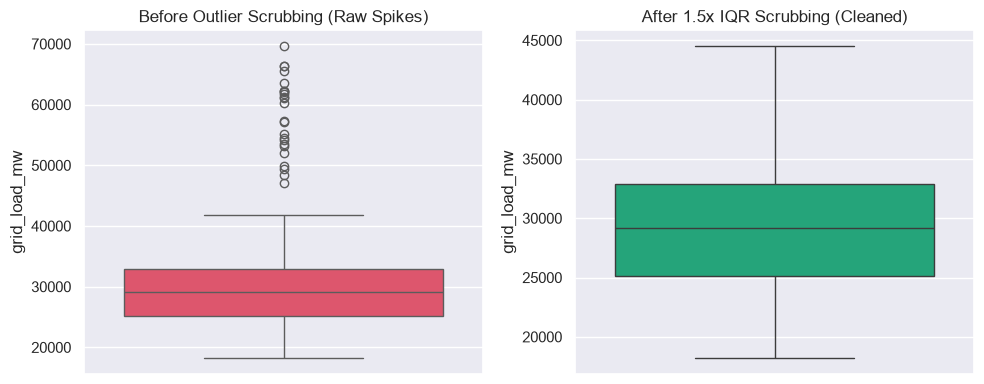

In [3]:
scrubbed_df, outlier_report = scrub_iqr_outliers(
    imputed_df, columns=['temperature_c', 'grid_load_mw'], iqr_multiplier=1.5, method='clip'
)
for col, info in outlier_report.items():
    print(f"{col:15s} -> Q1: {info['q1']}, Q3: {info['q3']}, IQR: {info['iqr']}, Lower: {info['lower_bound']}, Upper: {info['upper_bound']}, Scrubbed: {info['outliers_scrubbed']}")

# Boxplot before and after outlier scrubbing
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(y=raw_df['grid_load_mw'], ax=axes[0], color='#F43F5E')
axes[0].set_title('Before Outlier Scrubbing (Raw Spikes)')
sns.boxplot(y=scrubbed_df['grid_load_mw'], ax=axes[1], color='#10B981')
axes[1].set_title('After 1.5x IQR Scrubbing (Cleaned)')
plt.tight_layout()
plt.show()

## 3. Cyclical Temporal Feature Engineering (Unit III)
Preserving periodic continuity across midnight ($23:00 \to 00:00$):
$$h_{\sin} = \sin\left(\frac{2\pi \cdot \text{hour}}{24}\right), \quad h_{\cos} = \cos\left(\frac{2\pi \cdot \text{hour}}{24}\right)$$

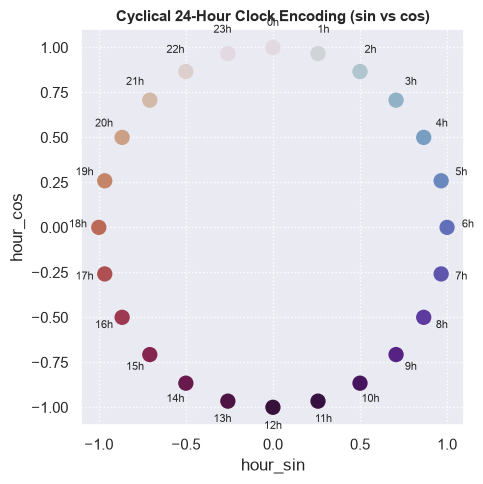

In [4]:
clean_df = add_cyclical_features(scrubbed_df)
plt.figure(figsize=(5, 5))
plt.scatter(clean_df['hour_sin'][:24], clean_df['hour_cos'][:24], c=clean_df['hour'][:24], cmap='twilight', s=100)
for i in range(24):
    plt.text(clean_df['hour_sin'][i]*1.12, clean_df['hour_cos'][i]*1.12, f"{clean_df['hour'][i]}h", fontsize=8, ha='center')
plt.title('Cyclical 24-Hour Clock Encoding (sin vs cos)', fontsize=11, fontweight='bold')
plt.xlabel('hour_sin')
plt.ylabel('hour_cos')
plt.grid(True, ls=':')
plt.tight_layout()
plt.show()

## 4. Welch's $t$-test (Unit III)
Testing whether peak operating hours exhibit statistically significantly dirtier electricity:
$$H_0: \mu_{\text{peak}} = \mu_{\text{off-peak}} \quad \text{vs.} \quad H_1: \mu_{\text{peak}} > \mu_{\text{off-peak}}$$

In [5]:
ttest_res = run_welchs_ttest(clean_df)
print(f"Peak Samples: {ttest_res['n_peak']}, Off-Peak Samples: {ttest_res['n_offpeak']}")
print(f"Peak Mean CI: {ttest_res['mean_peak']} gCO2/kWh, Off-Peak Mean CI: {ttest_res['mean_offpeak']} gCO2/kWh")
print(f"t-statistic: {ttest_res['t_statistic']}, degrees of freedom: {ttest_res['degrees_of_freedom']}")
print(f"One-sided p-value: {ttest_res['p_value_greater']:.2e}")
print(f"Verdict: {ttest_res['verdict']}")

Peak Samples: 1827, Off-Peak Samples: 6933
Peak Mean CI: 243.87 gCO2/kWh, Off-Peak Mean CI: 235.19 gCO2/kWh
t-statistic: 4.8545, degrees of freedom: 2955.6
One-sided p-value: 6.35e-07
Verdict: Reject H0 at alpha=0.05. Peak grid operating hours exhibit statistically significantly higher carbon intensity (+3.7% increase, p-value = 6.35e-07). Peak loads trigger dispatch of marginal fossil peaker plants.


## 5. Pure Python CSV Parser & Benchmarking (Unit IV)
Parsing CSV data using only built-in Python lists and dicts, then benchmarking against Pandas `read_csv`.

In [6]:
raw_path = '../data/raw/grid_telemetry_raw.csv'
bench = benchmark_csv_parsers(raw_path)
print(f"Rows parsed: {bench['num_rows']:,}, Columns: {bench['num_columns']}")
print(f"Pure Python parser time: {bench['pure_python_time_sec']} seconds")
print(f"Pandas read_csv time:     {bench['pandas_time_sec']} seconds")
print(f"Vectorized speedup factor: {bench['pandas_speedup_factor']}x")
print('\nFirst record from Pure Python parser:')
print(bench['python_sample_first_row'])

Rows parsed: 8,760, Columns: 21
Pure Python parser time: 0.6397 seconds
Pandas read_csv time:     0.0745 seconds
Vectorized speedup factor: 8.59x

First record from Pure Python parser:
{'timestamp': '2018-01-01 00:00:00', 'hour': 0, 'day_of_week': 0, 'day_name': 'Monday', 'is_weekend': 0, 'season': 'Winter', 'temperature_c': 11.31, 'grid_load_mw': 22779.0, 'gen_coal_mw': 996.0, 'gen_gas_mw': 3471.0, 'gen_biomass_mw': 282.0, 'gen_solar_mw': 9.0, 'gen_wind_mw': 12348.0, 'gen_nuclear_mw': 7057.0, 'gen_hydro_mw': 2238.0, 'total_generation_mw': 26401.0, 'carbon_intensity_gco2_per_kwh': 107.66, 'tariff_inr_per_kwh': 6.5, 'tariff_usd_per_kwh': 6.5, 'is_peak_hour': 0, 'grid_stress_label': 0}


## 6. NumPy Matrix Indexing & Slicing (Unit IV)
Demonstrating multi-dimensional NumPy array indexing, submatrix extraction, and boolean masking.

In [7]:
fuel_cols = ['gen_coal_mw', 'gen_gas_mw', 'gen_solar_mw', 'gen_wind_mw']
mat = clean_df[fuel_cols].values  # Shape: (8760, 4)
print('NumPy Matrix Shape:', mat.shape)
print('\nRow 0 generation vector:', mat[0, :])
print('\nFirst 3 rows, solar & wind columns (columns 2:4):\n', mat[:3, 2:4])
print('\nColumn-wise mean generation (MW):', np.mean(mat, axis=0))
print('\nMax generation across all fuels in first 100 hours:', np.max(mat[:100, :]))

NumPy Matrix Shape: (8760, 4)

Row 0 generation vector: [9.9600e+02 3.4710e+03 9.0000e+00 1.2348e+04]

First 3 rows, solar & wind columns (columns 2:4):
 [[9.0000e+00 1.2348e+04]
 [9.0000e+00 1.1156e+04]
 [9.0000e+00 9.4370e+03]]

Column-wise mean generation (MW): [4045.46130137 5817.54212329 1372.59611872 5585.25684932]

Max generation across all fuels in first 100 hours: 16063.0
